In [1]:
#[FE01] Load preprocessed dataset

import pandas as pd
import numpy as np

df_fe = pd.read_csv(
    "../data/processed/air_quality_cleaned.csv",
    parse_dates=["datetime"]
)

In [2]:
#[FE02] Create next-hour PM2.5 target

df_fe["target_pm25"] = df_fe["pm2.5"].shift(-1)

In [3]:
#[FE03] Check rows with available PM2.5 readings
df_fe.loc[df_fe["pm2.5"].notna(),
          ["datetime", "pm2.5", "target_pm25"]].head(10)

,datetime,pm2.5,target_pm25
24,2010-01-02 00:00:00,129.0,148.0
25,2010-01-02 01:00:00,148.0,159.0
26,2010-01-02 02:00:00,159.0,181.0
27,2010-01-02 03:00:00,181.0,138.0
28,2010-01-02 04:00:00,138.0,109.0
29,2010-01-02 05:00:00,109.0,105.0
30,2010-01-02 06:00:00,105.0,124.0
31,2010-01-02 07:00:00,124.0,120.0
32,2010-01-02 08:00:00,120.0,132.0
33,2010-01-02 09:00:00,132.0,140.0


In [4]:
#[FE04] Create previous-hour PM2.5 feature
df_fe["pm25_lag1"] = df_fe["pm2.5"].shift(1)

In [5]:
#[FE05] Extract day of the week
df_fe["day_of_week"] = df_fe["datetime"].dt.dayofweek

C:\Users\Mkosh\AppData\Local\Temp\ipykernel_47428\1200488371.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_fe["day_of_week"] = df_fe["datetime"].dt.dayofweek


In [6]:
#[FE06] Define model features and target

feature_cols = [
    "pm2.5",
    "pm25_lag1",
    "DEWP",
    "TEMP",
    "PRES",
    "Iws",
    "Is",
    "Ir",
    "cbwd_NW",
    "cbwd_SE",
    "cbwd_cv",
    "hour",
    "month",
    "day_of_week"
]

target_col = "target_pm25"

In [7]:
#[FE07] Create modelling dataset and remove missing values

df_model = df_fe[feature_cols + [target_col, "datetime"]].dropna().copy()

df_model = df_model.sort_values("datetime").reset_index(drop=True)

df_model.shape

(41348, 16)

In [8]:
#[FE08] Chronological train-test split

split_index = int(len(df_model) * 0.8)

split_time = df_model.loc[split_index, "datetime"]

train_df = df_model[
    df_model["datetime"].shift(-1) < split_time
].copy()

test_df = df_model[
    df_model["datetime"] >= split_time
].copy()

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

In [9]:
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training period:", train_df["datetime"].min(), "to", train_df["datetime"].max())
print("Testing period:", test_df["datetime"].min(), "to", test_df["datetime"].max())

Training observations: 33077
Testing observations: 8270
Training period: 2010-01-02 01:00:00 to 2014-01-14 16:00:00
Testing period: 2014-01-14 18:00:00 to 2014-12-31 22:00:00


In [10]:
#[FE09] Verify final modelling datasets

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nMissing values in training features:", X_train.isnull().sum().sum())
print("Missing values in testing features:", X_test.isnull().sum().sum())

print("\nFeature columns match:", list(X_train.columns) == list(X_test.columns))

X_train: (33077, 14)
y_train: (33077,)
X_test: (8270, 14)
y_test: (8270,)

Missing values in training features: 0
Missing values in testing features: 0

Feature columns match: True


In [17]:
#[MB01] Import regression models

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

print("Models imported successfully!")

Models imported successfully!


In [18]:
#[MB02] Train Linear Regression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [19]:
#[MB03] Train Random Forest

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [20]:
#[MB04] Generate predictions

y_pred_lr = lr_model.predict(X_test)

y_pred_rf = rf_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [21]:
#[MB05] Import evaluation metrics

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [22]:
#[MB06] Evaluate model performance

import numpy as np

# Linear Regression metrics
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_mse = mean_squared_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, y_pred_lr)

# Random Forest metrics
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, y_pred_rf)

print("LINEAR REGRESSION")
print("MAE:", lr_mae)
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R2:", lr_r2)

print("\nRANDOM FOREST")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2:", rf_r2)

LINEAR REGRESSION
MAE: 11.624959930179141
MSE: 454.38438061719353
RMSE: 21.31629378239082
R2: 0.9489800629439409

RANDOM FOREST
MAE: 11.85601330108827
MSE: 461.82726061668683
RMSE: 21.49016660281364
R2: 0.9481443492062148


In [23]:
#[MB07] Compare model performance

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [lr_mae, rf_mae],
    "MSE": [lr_mse, rf_mse],
    "RMSE": [lr_rmse, rf_rmse],
    "R2": [lr_r2, rf_r2]
})

results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,11.624960,454.384381,21.316294,0.948980
1,Random Forest,11.856013,461.827261,21.490167,0.948144


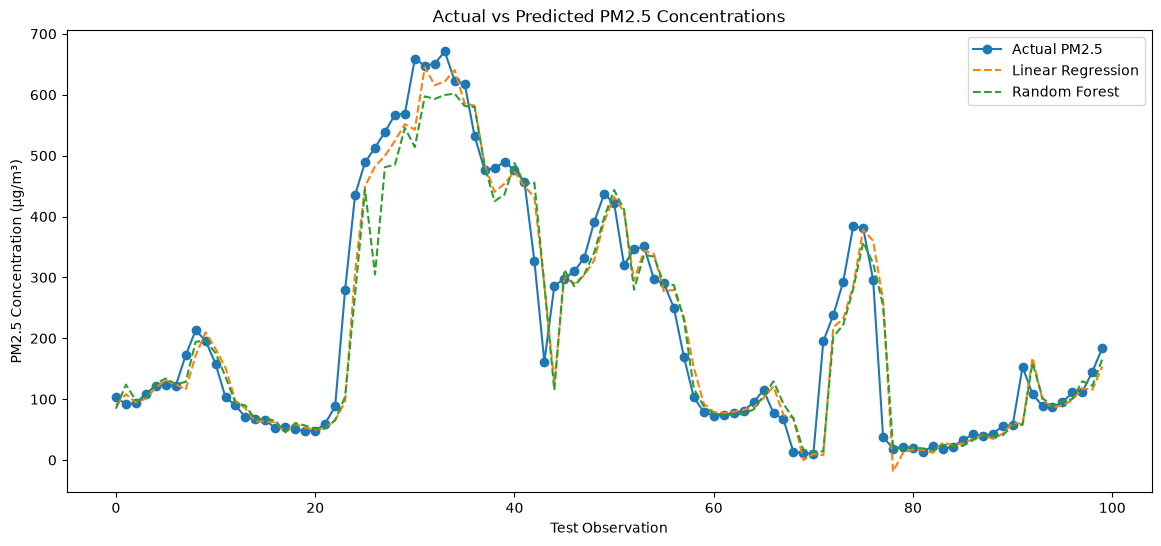

In [26]:
#[MB08] Actual vs Predicted PM2.5

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.iloc[:100].values,
    label="Actual PM2.5",
    marker="o"
)

plt.plot(
    y_pred_lr[:100],
    label="Linear Regression",
    linestyle="--"
)

plt.plot(
    y_pred_rf[:100],
    label="Random Forest",
    linestyle="--"
)

plt.title("Actual vs Predicted PM2.5 Concentrations")
plt.xlabel("Test Observation")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.legend()
plt.show()

In [27]:
#[MB09] Calculate prediction residuals

lr_residuals = y_test.values - y_pred_lr
rf_residuals = y_test.values - y_pred_rf

print("Linear Regression Mean Residual:", np.mean(lr_residuals))
print("Random Forest Mean Residual:", np.mean(rf_residuals))

Linear Regression Mean Residual: 0.008673279509505537
Random Forest Mean Residual: -0.6954885126964933


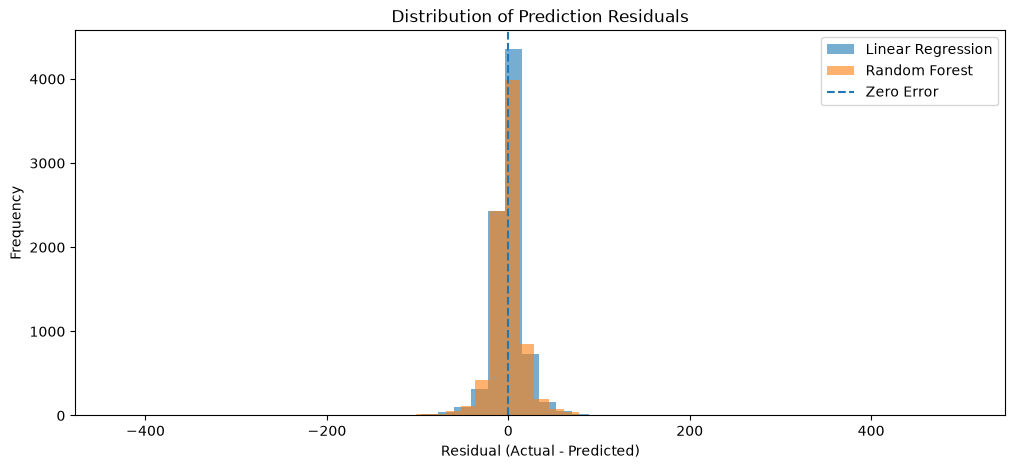

In [28]:
#[MB10] Plot residual distributions

plt.figure(figsize=(12, 5))

plt.hist(lr_residuals, bins=50, alpha=0.6,
         label="Linear Regression")

plt.hist(rf_residuals, bins=50, alpha=0.6,
         label="Random Forest")

plt.axvline(0, linestyle="--", label="Zero Error")

plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [29]:
#[MB11] Calculate Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,pm2.5,0.937095
1,pm25_lag1,0.017092
2,DEWP,0.009102
11,hour,0.006372
4,PRES,0.006358
5,Iws,0.006249
3,TEMP,0.006133
13,day_of_week,0.003536
12,month,0.003283
8,cbwd_NW,0.001919


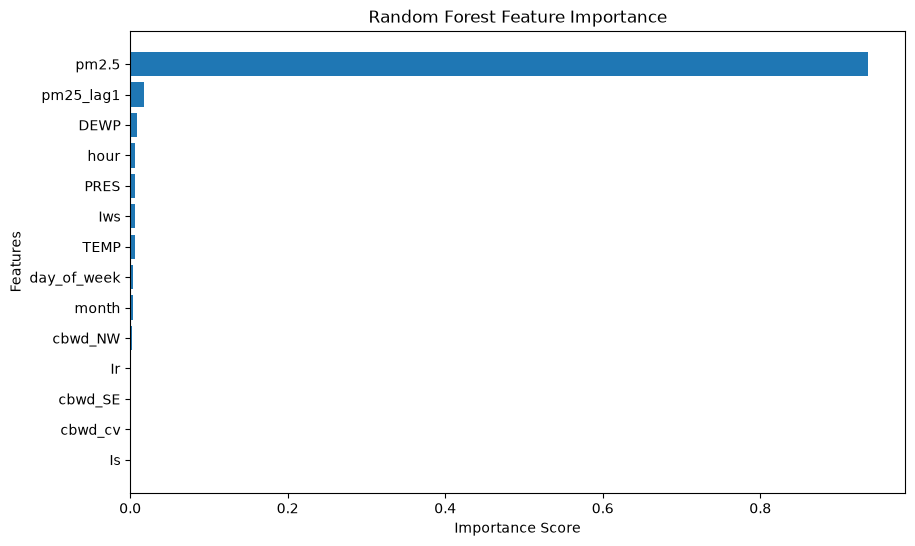

In [30]:
#[MB12] Plot Random Forest feature importance

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.show()

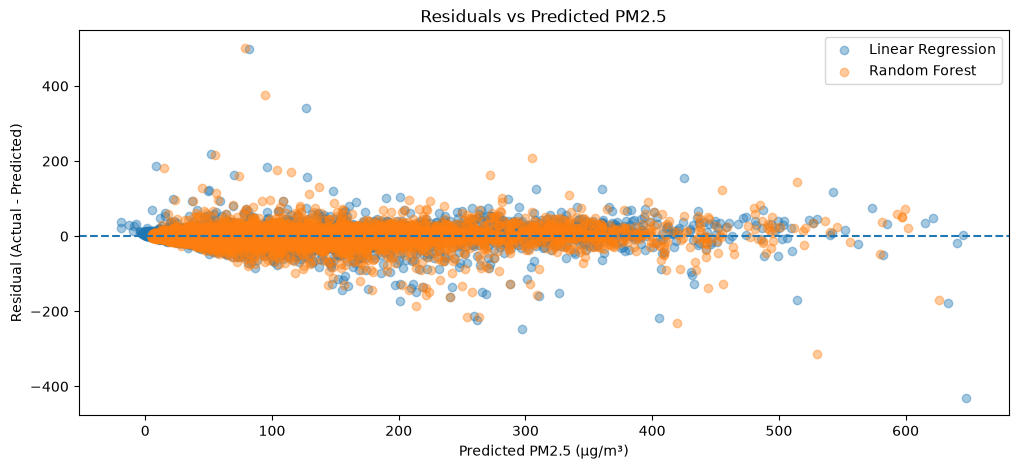

In [31]:
#[MB13] Plot residuals against predicted values

plt.figure(figsize=(12, 5))

plt.scatter(
    y_pred_lr,
    lr_residuals,
    alpha=0.4,
    label="Linear Regression"
)

plt.scatter(
    y_pred_rf,
    rf_residuals,
    alpha=0.4,
    label="Random Forest"
)

plt.axhline(0, linestyle="--")

plt.title("Residuals vs Predicted PM2.5")
plt.xlabel("Predicted PM2.5 (µg/m³)")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()

plt.show()

In [32]:
#[FD01] Save model comparison results

results.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [33]:
#[FD02] Save residuals vs predicted graph

import os

os.makedirs("../results/graphs", exist_ok=True)

plt.savefig(
    "../results/graphs/residuals_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

print("Residuals vs predicted graph saved!")

Residuals vs predicted graph saved!


<Figure size 640x480 with 0 Axes>

In [34]:
#[FD03] Save actual vs predicted graph

plt.savefig(
    "../results/graphs/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

print("Actual vs predicted graph saved!")

Actual vs predicted graph saved!


<Figure size 640x480 with 0 Axes>

In [35]:
#[FD04] Save residual distribution graph

plt.savefig(
    "../results/graphs/residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

print("Residual distribution graph saved!")

Residual distribution graph saved!


<Figure size 640x480 with 0 Axes>

In [36]:
#[FD05] Save feature importance graph

plt.savefig(
    "../results/graphs/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

print("Feature importance graph saved!")

Feature importance graph saved!


<Figure size 640x480 with 0 Axes>

In [37]:
#[FD06] Verify saved results

import os

print("RESULTS FOLDER")
print(os.listdir("../results"))

print("\nGRAPHS FOLDER")
print(os.listdir("../results/graphs"))

RESULTS FOLDER
['graphs', 'model_comparison.csv']

GRAPHS FOLDER
['actual_vs_predicted.png', 'feature_importance.png', 'residuals_vs_predicted.png', 'residual_distribution.png']
